# Investigate alleles that increased abundance

Almost all variants with abundance changes that surpass assay variability are decreases in abundance. For the very few cases that increased abundance, we want to see if there is anything biologically interesting going on here.

In [36]:
import polars as pl
import sys
import seaborn as sns
from matplotlib import pyplot as plt
import pandas as pd
import sys
sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

In [37]:
outputs_dir = "../3_outputs"

## 1. Variants with increased abundance

In [38]:
scores = pl.read_csv(f"{outputs_dir}/annotated_perturbation_scores.csv", infer_schema_length=1000000)
incr_abun = scores.filter(pl.col("dualipa_abun_score") > 1.96)
print(incr_abun.select(['symbol', 'aa_change', 'dualipa_abun_score', 'clinvar_clnsig_clean', 'StarStatus']))

shape: (63, 5)
┌────────┬───────────┬────────────────────┬──────────────────────┬────────────┐
│ symbol ┆ aa_change ┆ dualipa_abun_score ┆ clinvar_clnsig_clean ┆ StarStatus │
│ ---    ┆ ---       ┆ ---                ┆ ---                  ┆ ---        │
│ str    ┆ str       ┆ f64                ┆ str                  ┆ f64        │
╞════════╪═══════════╪════════════════════╪══════════════════════╪════════════╡
│ SH3BP2 ┆ Gly420Arg ┆ 3.843193           ┆ 1_Pathogenic         ┆ null       │
│ BAG3   ┆ Arg477His ┆ 3.244457           ┆ 3_Conflicting        ┆ 1.0        │
│ NT5C3A ┆ Gly275Arg ┆ 2.527659           ┆ 1_Pathogenic         ┆ null       │
│ NAA10  ┆ Arg116Trp ┆ 4.352335           ┆ 1_Pathogenic         ┆ 2.0        │
│ MID1   ┆ Pro151Leu ┆ 5.624762           ┆ 4_VUS                ┆ 1.0        │
│ …      ┆ …         ┆ …                  ┆ …                    ┆ …          │
│ EMD    ┆ Met1Val   ┆ 2.582952           ┆ 1_Pathogenic         ┆ 2.0        │
│ KRT6A  ┆ Asn21Ser  ┆ 2.

## 2. Group the variants by gene

In [39]:
symbol_medians = scores.filter(~pl.col("dualipa_abun_score").is_null()).group_by("symbol").agg(
    pl.col("dualipa_abun_score").mean().alias("gene_mean")
).sort("gene_mean")

symbol_order = symbol_medians.select('symbol').to_series().to_list()
scores_plot = scores.join(symbol_medians, on="symbol").to_pandas()
scores_plot['symbol'] = pd.Categorical(scores_plot['symbol'], categories=symbol_order, ordered=True)
scores_plot

,symbol,node_type,nt_change,aa_change,pla,well,coordinates,n_cells,orf_id,mut_id,...,zscore_median,zcat_median,zscore_log2fc_median_norm_by_each_wt,dualipa_abun_score,dualipa_abun_change,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category,gene_mean
0,KCNJ2,allele,899G>A,Gly300Asp,11,D07,11_D07,8822,100016069,2641,...,-1.875327,-1.0,-5.589107,-7.844631,1,94.45,0.059524,<10,>90,-7.132054
1,HBD,allele,174C>A,Asn58Lys,26,E05,26_E05,9609,13796,218146,...,-1.877915,-1.0,-5.612572,-10.990479,1,98.57,0.076433,<10,>90,-11.271441
2,SMAD3,allele,376C>T,His126Tyr,20,H03,20_H03,9096,11805,2128,...,-1.658717,-1.0,-4.073922,-5.538377,0,97.82,0.021739,<10,>90,-3.165070
3,HBD,allele,110C>A,Pro37His,26,D05,26_D05,9403,13796,218145,...,-1.984698,-1.0,-6.779881,-12.385791,1,97.87,0.536765,10-90,>90,-11.271441
4,KRT2,allele,558C>A,Asn186Lys,3,B10,3_B10,11251,55855,30963,...,-1.537580,-1.0,-3.468007,-7.742482,1,84.92,0.573248,10-90,70-90,-6.152709
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
758,ACSF3,allele,1075G>A,Glu359Lys,10,F09,10_F09,11224,71337,205770,...,-0.119903,0.0,0.009240,-0.912171,0,96.68,0.067010,<10,>90,-2.251474
759,SMAD3,allele,788C>T,Pro263Leu,20,G11,20_G11,9399,11805,203607,...,-0.615137,0.0,-0.821836,-3.002500,0,92.14,0.801471,10-90,>90,-3.165070
760,GCK,allele,131G>A,Gly44Asp,12,F01,12_F01,8784,3689,214816,...,-0.567097,0.0,-0.730674,-0.292284,0,97.95,0.000000,<10,>90,-4.022184
761,COMP,allele,1042T>C,Cys348Arg,3,E04,3_E04,13933,56661,219631,...,0.395451,0.0,0.687125,0.858717,0,96.48,0.274074,10-90,>90,-0.177177


In [40]:
dual_ipa_df = pl.DataFrame(scores_plot)
dual_gene = dual_ipa_df.group_by(
    ["symbol"]
).len().rename(
    {"len": "total_counts_all"}
).sort("total_counts_all", descending=True)

<Figure size 640x480 with 0 Axes>

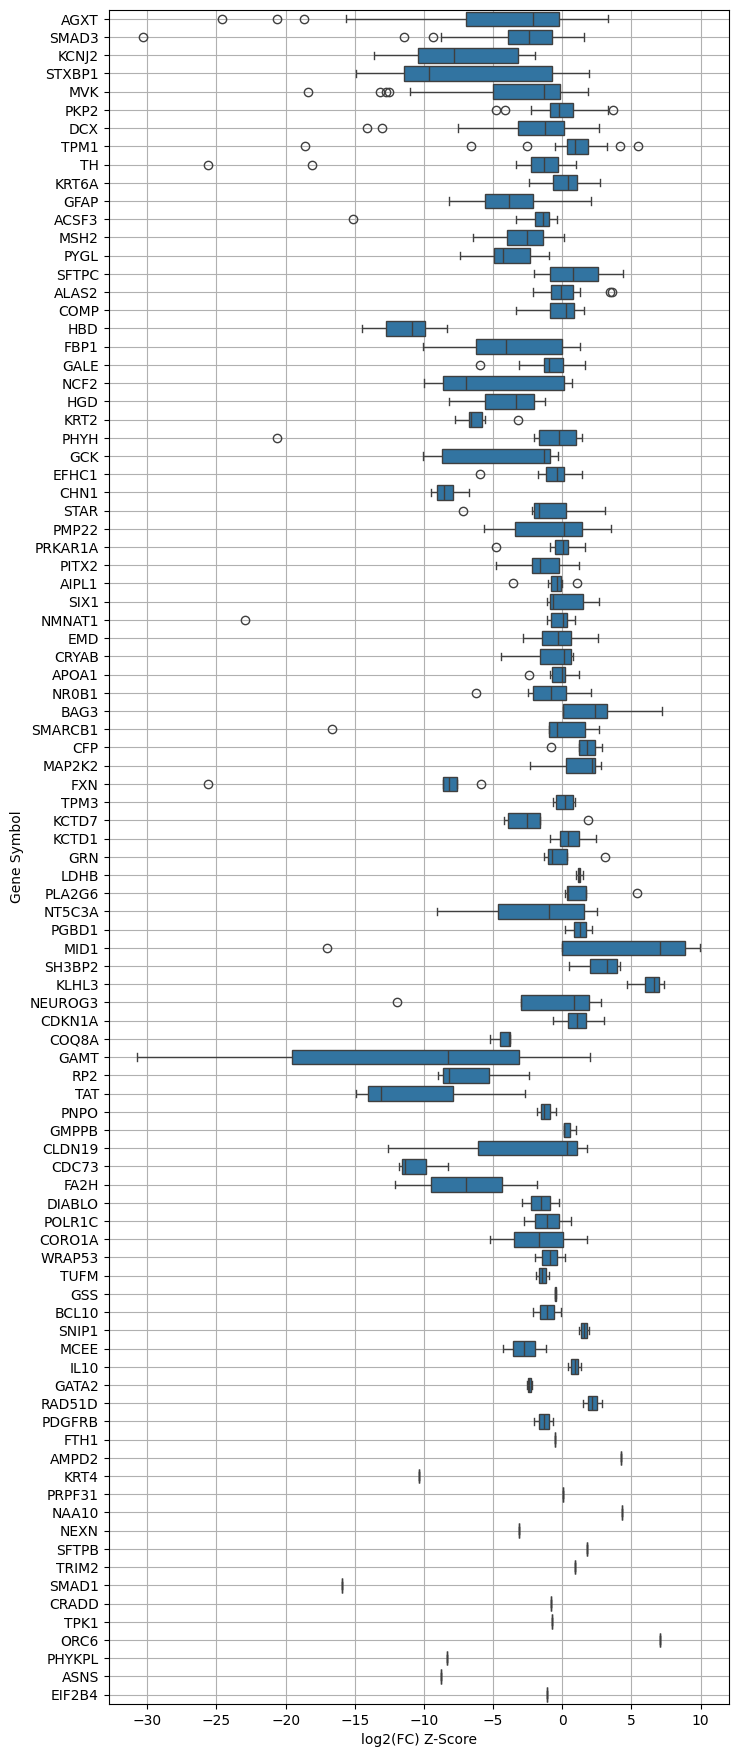

In [41]:
plt.clf()
fig, ax = plt.subplots(1,1,figsize=(8, 22))
sns.boxplot(data=scores_plot, x="dualipa_abun_score", y="symbol", ax=ax, order=dual_gene["symbol"])
ax.set_xlabel("log2(FC) Z-Score")
ax.set_ylabel("Gene Symbol")
ax.grid()
plt.show()

<Figure size 640x480 with 0 Axes>

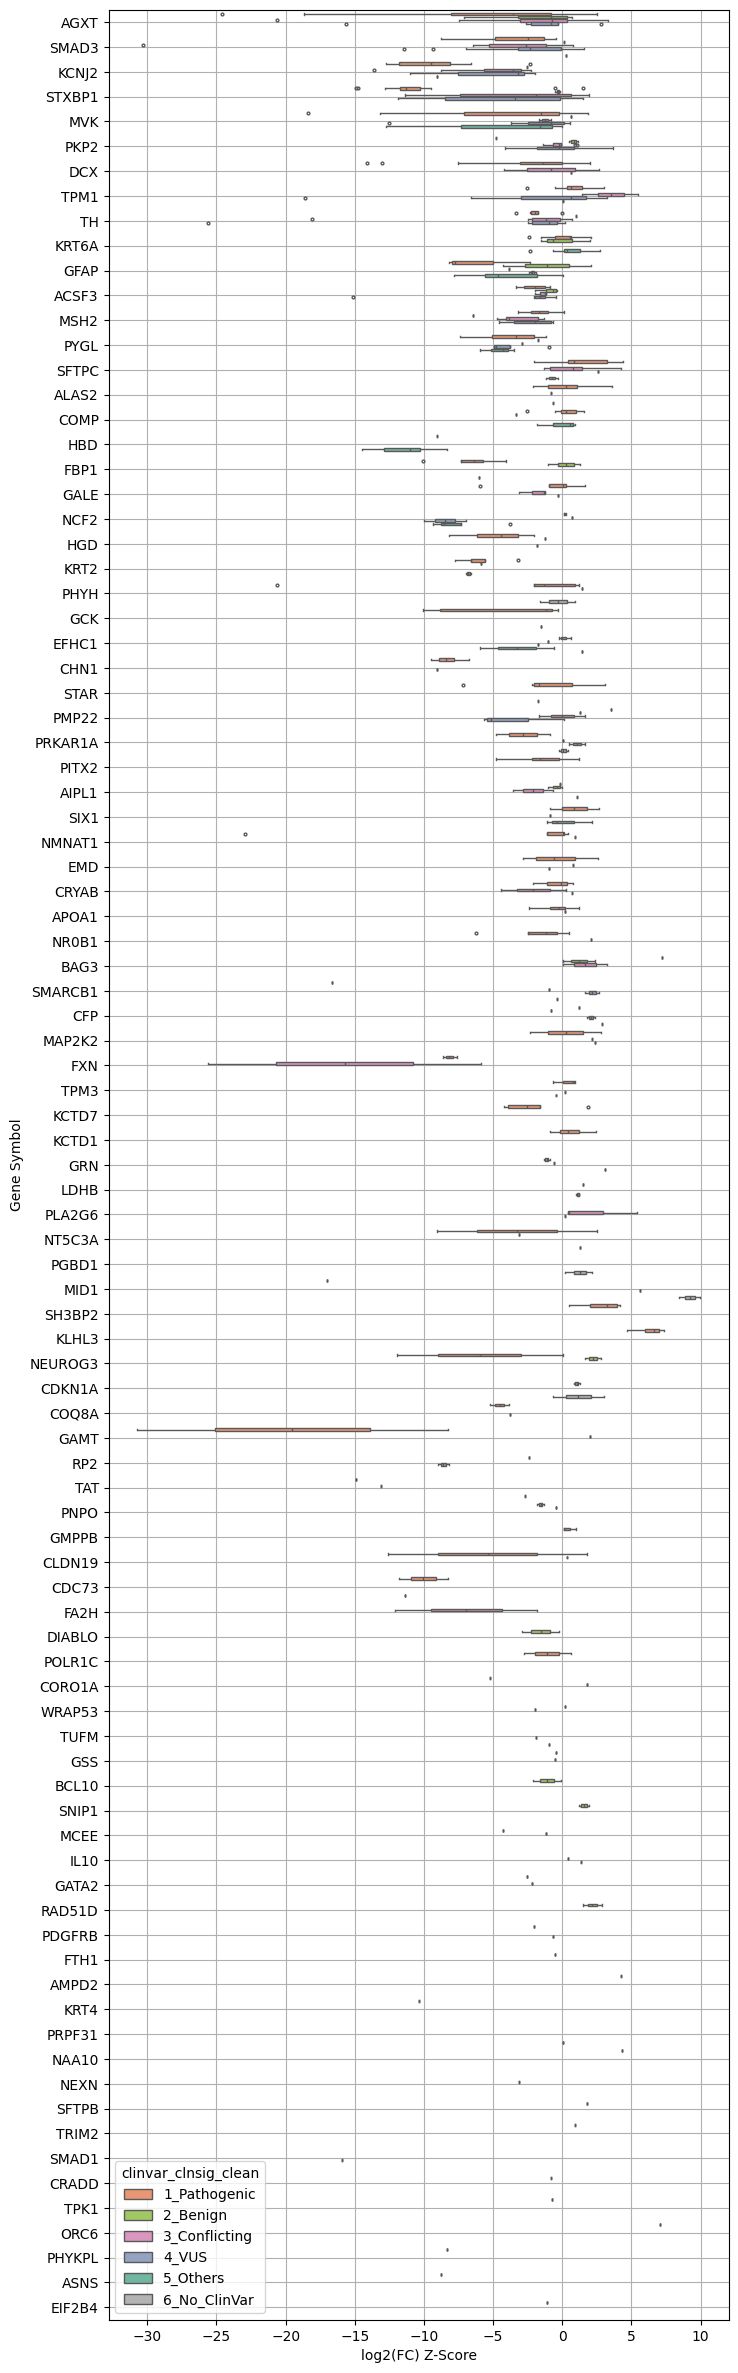

In [42]:
plt.clf()
fig, ax = plt.subplots(1,1,figsize=(8, 30))
sns.boxplot(data=scores_plot, x="dualipa_abun_score", y="symbol", 
            palette=palette_dict["clinvar_clnsig_clean"], ax=ax, 
            hue="clinvar_clnsig_clean", 
            hue_order=sorted(scores_plot.dropna(subset="clinvar_clnsig_clean")["clinvar_clnsig_clean"].unique()),
            gap=.2,
            fliersize=2,
            order=dual_gene["symbol"]
           )

ax.set_xlabel("log2(FC) Z-Score")
ax.set_ylabel("Gene Symbol")
ax.grid()
plt.show()

<Figure size 640x480 with 0 Axes>

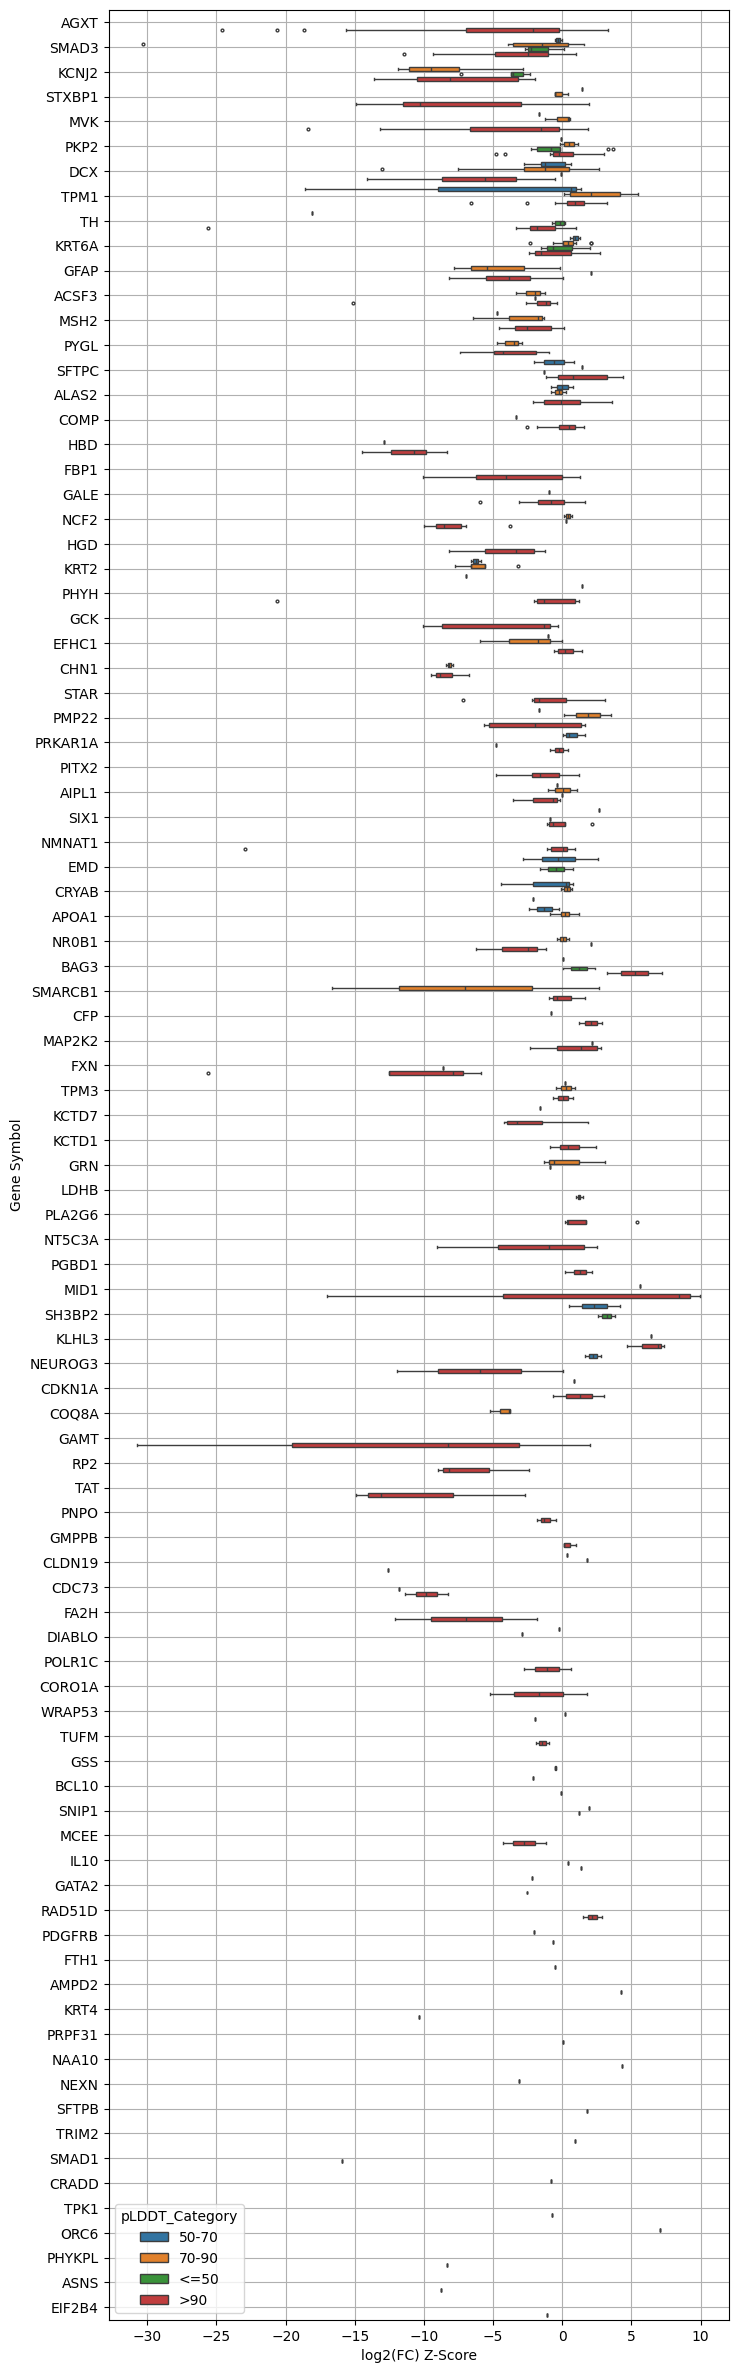

In [43]:
plt.clf()
fig, ax = plt.subplots(1,1,figsize=(8, 30))
sns.boxplot(data=scores_plot, x="dualipa_abun_score", y="symbol", 
            ax=ax, 
            hue="pLDDT_Category", 
            hue_order=sorted(scores_plot.dropna(subset="pLDDT_Category")["pLDDT_Category"].unique()),
            gap=.2,
            fliersize=2,
            order=dual_gene["symbol"]
           )

ax.set_xlabel("log2(FC) Z-Score")
ax.set_ylabel("Gene Symbol")
ax.grid()
plt.show()

<Figure size 640x480 with 0 Axes>

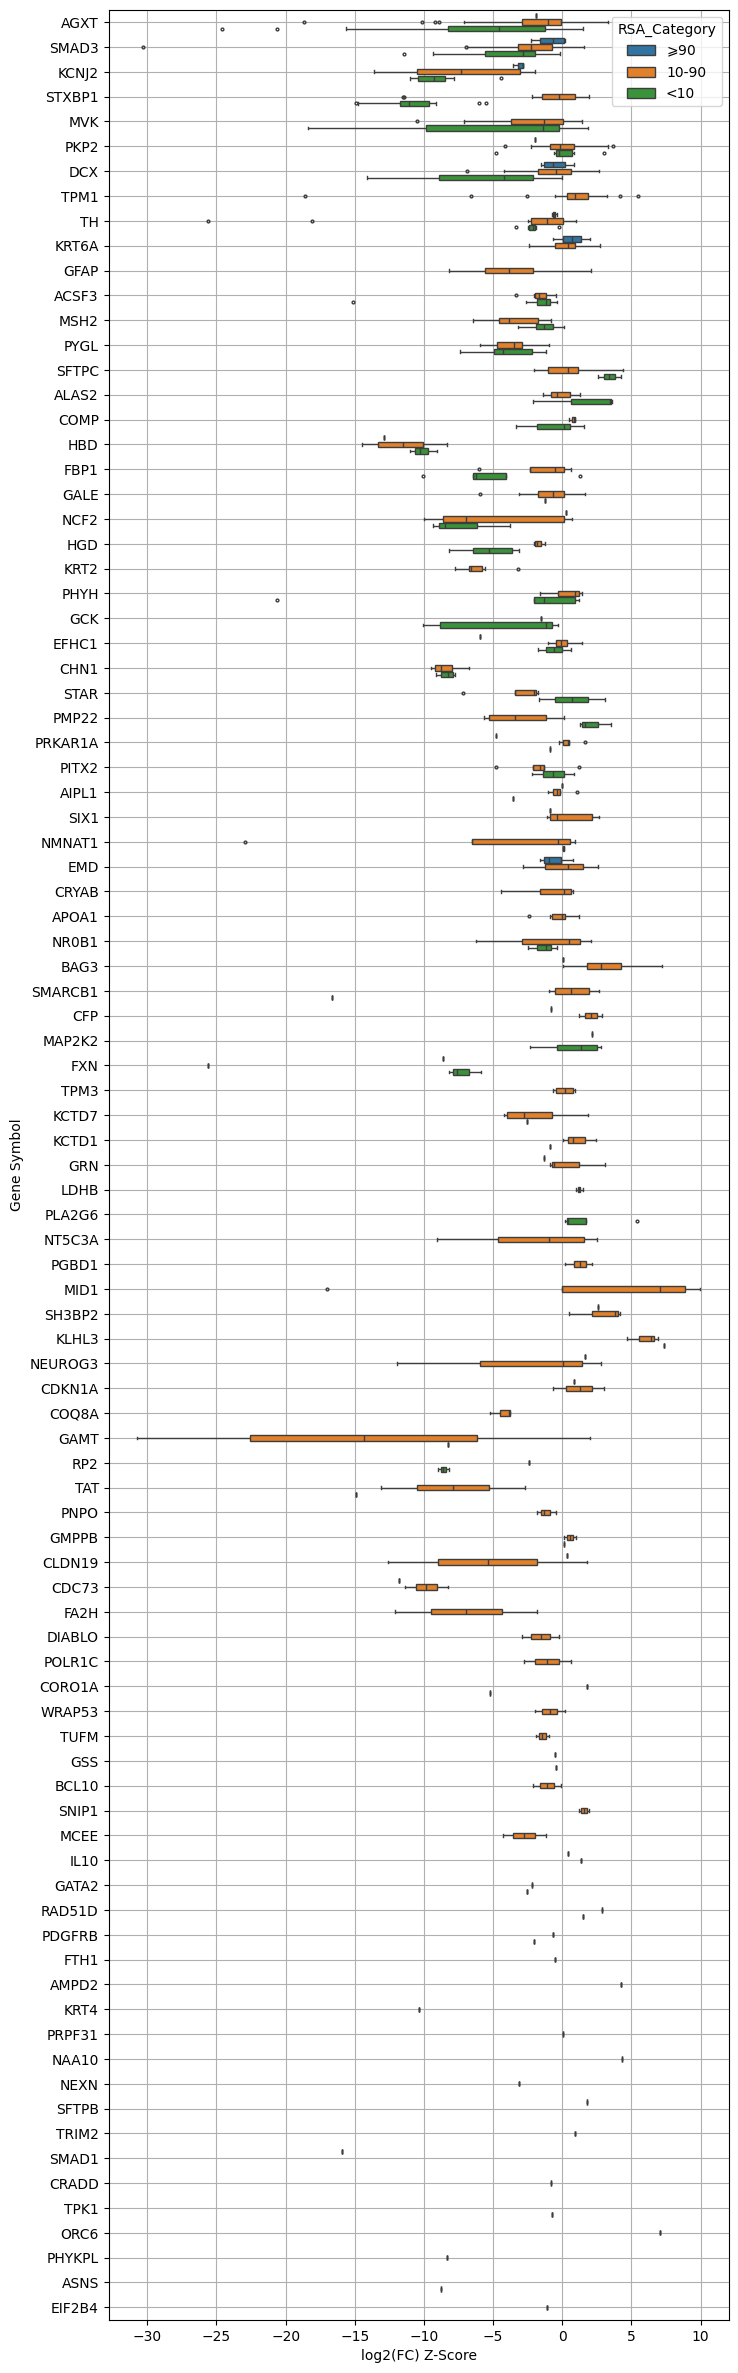

In [44]:
plt.clf()
fig, ax = plt.subplots(1,1,figsize=(8, 30))
sns.boxplot(data=scores_plot, x="dualipa_abun_score", y="symbol", 
            ax=ax, 
            hue="RSA_Category", 
            hue_order=sorted(scores_plot.dropna(subset="RSA_Category")["RSA_Category"].unique()),
            gap=.2,
            fliersize=2,
            order=dual_gene["symbol"]
           )

ax.set_xlabel("log2(FC) Z-Score")
ax.set_ylabel("Gene Symbol")
ax.grid()
plt.show()

## 3. Plot hits

In [45]:
def plot_gene_level_summary(total_allele_hit_sum_df, assay, xlim=None, cat="clinvar_clnsig_clean"):
    # Convert to pandas and sort
    total_allele_hit_sum_df = total_allele_hit_sum_df.to_pandas().reset_index(drop=True)
    n_genes = len(total_allele_hit_sum_df)
    
    # Dynamically scale figure size
    fig_height = max(6, min(n_genes * 0.3, 40))
    fig_width = 6  # Slightly wider to accommodate labels
    
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    # Create the barplots
    # Total counts (background bars)
    sns.barplot(
        data=total_allele_hit_sum_df, 
        y="symbol", 
        x="total_counts", 
        hue=cat,  # "clinvar_clnsig_clean"
        palette="Set2" if cat not in palette_dict else palette_dict[cat],
        alpha=0.6,  # Make background bars slightly transparent
        ax=ax,
        # gap=.1,
        order=total_allele_hit_sum_df["symbol"].drop_duplicates()
    )
    # Hit counts (foreground bars)
    sns.barplot(
        data=total_allele_hit_sum_df, 
        y="symbol", 
        x="hit_counts", 
        hue=cat,#"clinvar_clnsig_clean", 
        palette="Set2" if cat not in palette_dict else ["orange","forestgreen"],
        ax=ax,
        # gap=.1,
        order=total_allele_hit_sum_df["symbol"].drop_duplicates()
    )
    
    # Add percentage labels
    # Get unique categories and their positions
    categories = total_allele_hit_sum_df[cat].unique()
    n_categories = len(categories)
    
    # Calculate bar positions for each category
    bar_height = 0.8 / n_categories  # Default seaborn bar height divided by number of categories
    
    for i, gene in enumerate(total_allele_hit_sum_df["symbol"].unique()):
        gene_data = total_allele_hit_sum_df[total_allele_hit_sum_df["symbol"] == gene]
        for j, category in enumerate(categories):
            cat_data = gene_data[gene_data[cat] == category]
            if not cat_data.empty:
                # Calculate bar position
                bar_center = i + (j - (n_categories - 1) / 2) * bar_height
                # print(bar_center)
                # print(bar_center)
                # Get the hit percentage value
                hit_perc = cat_data["hit_perc"].iloc[0]
                hit_counts = cat_data["hit_counts"].iloc[0]
                # Add percentage label at the end of the hit_counts bar
                ax.text(
                    hit_counts + max(total_allele_hit_sum_df["hit_counts"]) * 0.01,  # Small offset
                    bar_center,
                    f"{hit_perc:.1f}%",
                    ha="left",
                    va="center",
                    fontsize=9 if n_genes > 20 else 10,
                    fontweight="bold"
                )
    
    # # Formatting
    ax.grid(alpha=0.2, axis='x')
    ax.set_xlabel("Count", fontsize=11)
    ax.set_ylabel("Gene Symbol", fontsize=11)
    ax.set_title(f"{assay}", fontsize=13)
    
    # # Adjust x-axis limit to accommodate labels
    # max_count = max(total_allele_hit_sum_df["total_counts"].max(), 
    #                 total_allele_hit_sum_df["hit_counts"].max())
    # ax.set_xlim(0, max_count * 1.15)
    
    # Improve legend
    handles, labels = ax.get_legend_handles_labels()
    # Remove duplicate legend entries (seaborn creates duplicates with multiple barplots)
    unique_labels = []
    unique_handles = []
    for handle, label in zip(handles, labels):
        if label not in unique_labels:
            unique_labels.append(label)
            unique_handles.append(handle)
    
    ax.legend(unique_handles, unique_labels, 
              title=cat, 
              fontsize=10, 
              loc="lower right",
              framealpha=0.9)
    if xlim:
        ax.set_xlim(xlim)
        
    plt.tight_layout()
    plt.show()
    
    return total_allele_hit_sum_df

### 3.1 Plot hits by ClinVar

In [46]:
dual_ipa_df.filter((pl.col("dualipa_abun_change")==1))

symbol,node_type,nt_change,aa_change,pla,well,coordinates,n_cells,orf_id,mut_id,valid_well,avg_gfp,avg_mcherry,avg_GFP_mCherry_ratio,wt_GFP_mCherry_ratio,allele_wt_ratio,zscore,zcat,allele_wt_log2fc,zscore_log2fc_mean_norm_by_all_wt_mean,allele_wt_log2fc_pvalue,zscore_log2fc_mean_norm_by_each_wt,symbol_right,ensembl_gene_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change_right,aa_change_right,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,…,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs,inheritance_pattern,disease_modules,disease_module_count,OMIM_disease_names,gene_allele,median_gfp,median_mcherry,median_GFP_mCherry_ratio,wt_GFP_mCherry_ratio_median,allele_wt_ratio_median,zscore_median,zcat_median,zscore_log2fc_median_norm_by_each_wt,dualipa_abun_score,dualipa_abun_change,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category,gene_mean
cat,str,str,str,i64,str,str,i64,i64,i64,bool,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,…,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,f64,f64,str,str,str,i64,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64,str,str,f64
"""KCNJ2""","""allele""","""899G>A""","""Gly300Asp""",11,"""D07""","""11_D07""",8822,100016069,2641,true,1801.536166,6450.702463,0.526546,1.862762,0.282669,-2.547858,-2,-1.822812,-7.844631,4.3423e-15,-4.608617,"""KCNJ2""","""ENSG00000123700""","""CCSBVarC008343""","""ALE00008329""","""NC_000017.11:70175938:G:A""","""899G>A""","""Gly300Asp""","""Edgotyping3""","""VUSMutGDEh010""","""G06""","""GDEhDisVCh_40005""","""F10""",1.0,"""VUSMutGDDh010""","""G06""",…,"""-""","""-""","""-""","""-""","""-""","""-""","""SCV001446813|SCV004571381""","""-""","""-""","""899G>A ""","""Gly300Asp""","""NM_000891.3""",2.0,"""1_Pathogenic""",94.45,0.059524,"""['170390', '609622', '170390']""","""autosomal dominant""","""Rare genetic cardiac disease; …",2,"""ANDERSEN CARDIODYSRHYTHMIC PER…","""KCNJ2_Gly300Asp""",693.679993,5069.049805,0.133067,0.841771,0.15808,-1.875327,-1.0,-5.589107,-7.844631,1,94.45,0.059524,"""<10""",""">90""",-7.132054
"""HBD""","""allele""","""174C>A""","""Asn58Lys""",26,"""E05""","""26_E05""",9609,13796,218146,true,43.352592,5031.259545,0.020272,0.118448,0.171143,-2.93378,-2,-2.546728,-10.990479,4.2467e-28,-6.465333,"""HBD""","""ENSG00000223609""","""CCSBVarC006560""","""ALE00006559""","""NC_000011.10:5234132:G:T""","""174C>A""","""Asn58Lys""","""CEGS2""","""CegsMutGDEh1047""","""D02""","""GDEhDisVCh_40036""","""D03""",2.0,"""CegsMutGDDh1047""","""D02""",…,"""-""","""-""","""-""","""-""","""-""","""-""","""SCV000036502""","""-""","""-""","""174C>A ""","""Asn58Lys""","""NM_000519.4""",null,"""5_Others""",98.57,0.076433,null,null,"""Rare genetic hematologic disea…",1,null,"""HBD_Asn58Lys""",33.84,2474.280029,0.012192,0.077713,0.156882,-1.877915,-1.0,-5.612572,-10.990479,1,98.57,0.076433,"""<10""",""">90""",-11.271441
"""HBD""","""allele""","""110C>A""","""Pro37His""",26,"""D05""","""26_D05""",9403,13796,218145,true,41.427022,7790.637677,0.016227,0.118448,0.136994,-3.051946,-2,-2.867814,-12.385791,3.1199e-35,-7.288862,"""HBD""","""ENSG00000223609""","""CCSBVarC006559""","""ALE00006558""","""NC_000011.10:5234196:G:T""","""110C>A""","""Pro37His""","""CEGS2""","""CegsMutGDEh1046""","""E11""","""GDEhDisVCh_40036""","""C03""",2.0,"""CegsMutGDDh1046""","""E11""",…,"""-""","""-""","""-""","""-""","""-""","""-""","""SCV000036501""","""-""","""-""","""110C>A ""","""Pro37His""","""NM_000519.4""",null,"""5_Others""",97.87,0.536765,null,null,"""Rare ge

In [47]:
dual_clean_all = dual_ipa_df.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS", "5_Others"]) ## ,
).group_by(
    ["clinvar_clnsig_clean"]
).len().rename(
    {"len": "total_counts"}
)

dual_clean_hits_all = dual_ipa_df.filter(
    (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS", "5_Others"])) & (pl.col("dualipa_abun_change")==1) ##
).group_by(
    ["clinvar_clnsig_clean"]
).len().rename(
    {"len": "hit_counts"}
)

dual_hits_all = dual_clean_all.join(
    dual_clean_hits_all,
    on=["clinvar_clnsig_clean"],
    how="left"
).fill_null(0).with_columns(
    (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
)
plot_df = dual_hits_all.sort("clinvar_clnsig_clean").to_pandas()
plot_df

# fig, axes = plt.subplots(1,2,figsize=(10,4))
# sns.barplot(plot_df, y="clinvar_clnsig_clean",
#             x="total_counts", color="steelblue",
#             label="Total count", ax=axes[0])
# sns.barplot(plot_df, y="clinvar_clnsig_clean",
#                  x="hit_counts", color="tomato",
#                  label="Hit count", ax=axes[0])
# axes[0].set_title(f"Protein Mislocalization Hits Strict")
# # Add percentage annotations
# for i, row in plot_df.iterrows():
#     # Position the text at the end of the red (hit_counts) bar
#     axes[0].text(row['hit_counts'] + max(plot_df['total_counts']) * 0.01,  # slight offset from bar end
#             i,  # y position (bar index)
#             f"{row['hit_perc']:.1f}%",  # percentage text
#             va='center',  # vertical alignment
#             ha='left',   # horizontal alignment
#             fontweight='bold',
#            fontsize=12,
#            color="black")
# axes[0].grid(alpha=.2)
# plt.show()

,clinvar_clnsig_clean,total_counts,hit_counts,hit_perc
0,1_Pathogenic,348,90,25.862069
1,2_Benign,70,0,0.000000
2,3_Conflicting,124,11,8.870968
3,4_VUS,133,17,12.781955
4,5_Others,61,16,26.229508


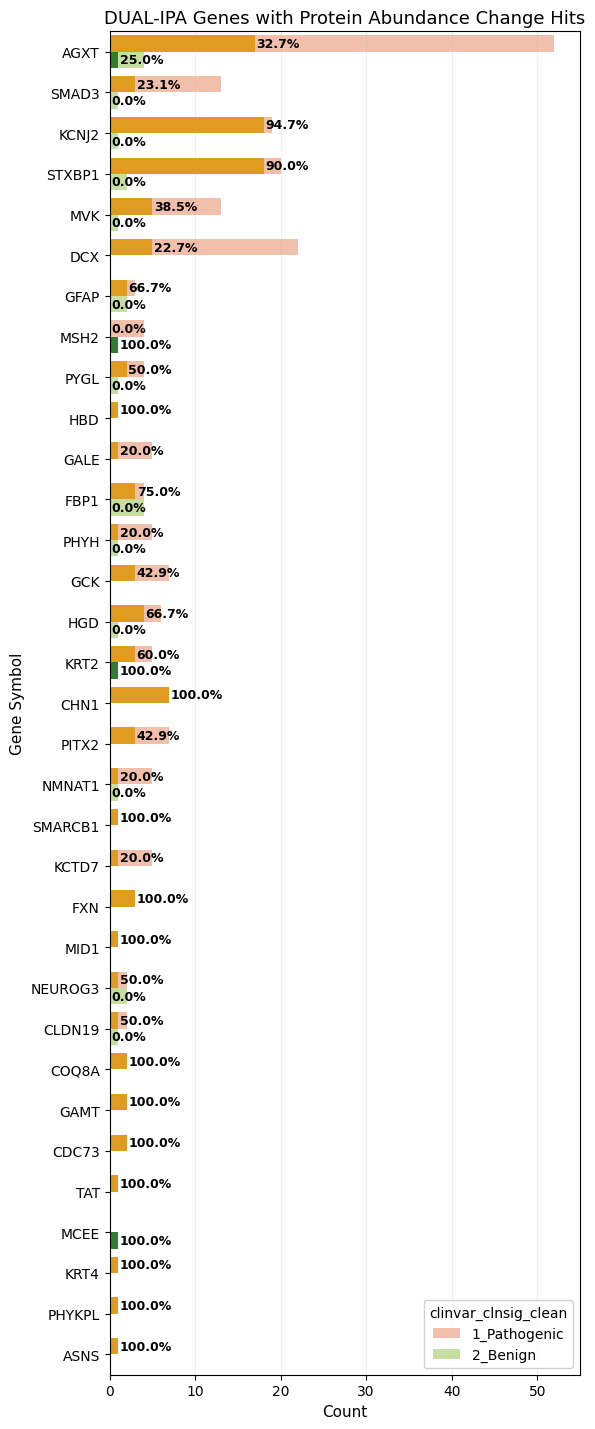

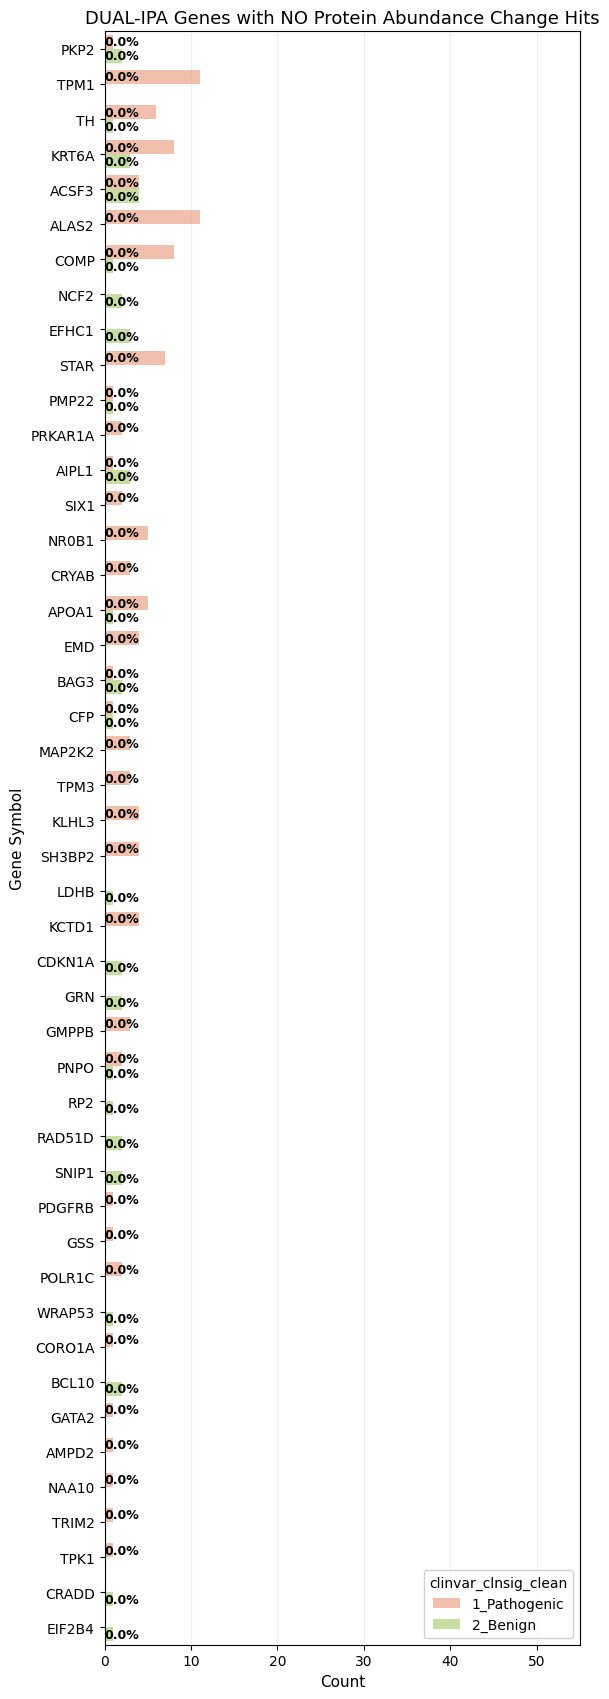

In [171]:
genes_with_hits = dual_hits_all.filter(pl.col("hit_perc")>0)["symbol"].unique()

dual_hits_all_res = plot_gene_level_summary(dual_hits_all.filter(pl.col("symbol").is_in(genes_with_hits)), "DUAL-IPA Genes with Protein Abundance Change Hits", xlim=(0,55))
dual_hits_no_res = plot_gene_level_summary(dual_hits_all.filter(~pl.col("symbol").is_in(genes_with_hits)).sort(
    "total_counts_all","symbol","clinvar_clnsig_clean", 
    descending=[True, True, False]
), "DUAL-IPA Genes with NO Protein Abundance Change Hits", xlim=(0,55))

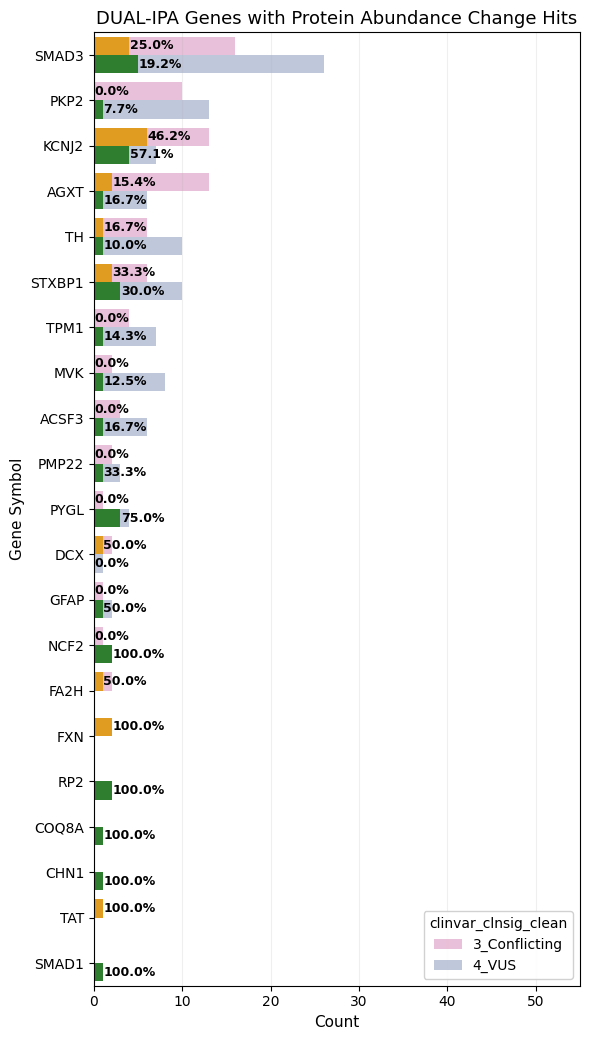

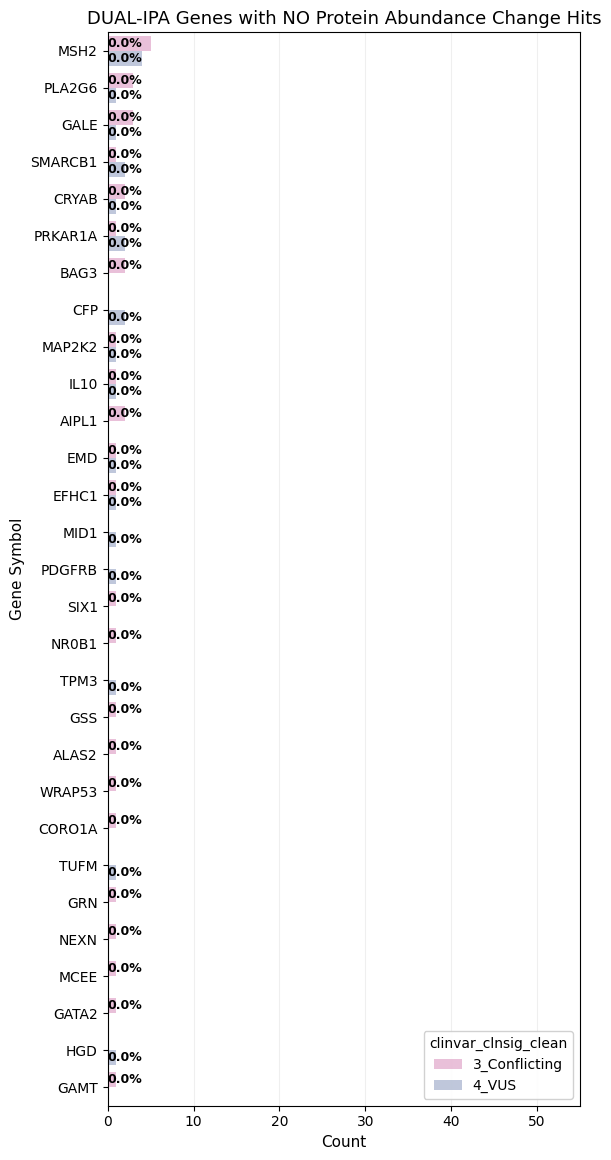

In [172]:
dual_gene = dual_ipa_df.filter(
    pl.col("clinvar_clnsig_clean").is_in(["3_Conflicting","4_VUS"]) ## ,
).group_by(
    ["symbol"]
).len().rename(
    {"len": "total_counts_all"}
)

dual_clean_all = dual_ipa_df.filter(
    pl.col("clinvar_clnsig_clean").is_in(["3_Conflicting","4_VUS"]) ## ,"3_Conflicting","4_VUS"
).group_by(
    ["symbol","clinvar_clnsig_clean"]
).len().rename(
    {"len": "total_counts"}
)

dual_clean_hits_all = dual_ipa_df.filter(
    (pl.col("clinvar_clnsig_clean").is_in(["3_Conflicting","4_VUS"])) & (pl.col("dualipa_abund_change")) ##,"3_Conflicting","4_VUS"
).group_by(
    ["symbol","clinvar_clnsig_clean"]
).len().rename(
    {"len": "hit_counts"}
)

dual_hits_all = dual_clean_all.join(
    dual_clean_hits_all,
    on=["symbol","clinvar_clnsig_clean"],
    how="left"
).fill_null(0).with_columns(
    (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
).join(dual_gene, on="symbol").sort(
    "total_counts_all","symbol","clinvar_clnsig_clean", 
    descending=[True, True, False]
)

genes_with_hits = dual_hits_all.filter(pl.col("hit_perc")>0)["symbol"].unique()

dual_hits_all_res = plot_gene_level_summary(dual_hits_all.filter(pl.col("symbol").is_in(genes_with_hits)), "DUAL-IPA Genes with Protein Abundance Change Hits", xlim=(0,55))
dual_hits_no_res = plot_gene_level_summary(dual_hits_all.filter(~pl.col("symbol").is_in(genes_with_hits)).sort(
    "total_counts_all","symbol","clinvar_clnsig_clean", 
    descending=[True, True, False]
), "DUAL-IPA Genes with NO Protein Abundance Change Hits", xlim=(0,55))

### 3.2 Plot hits by structural info

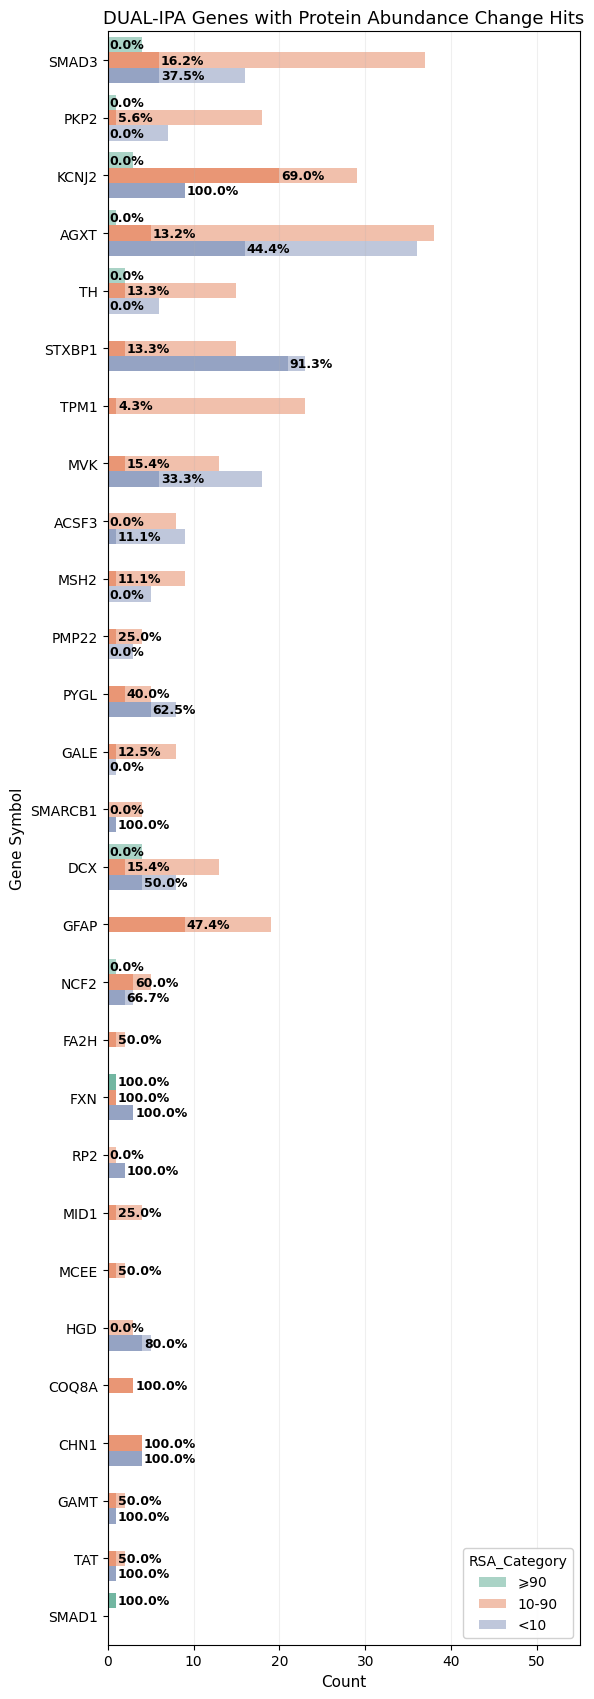

In [181]:
dual_clean_all = dual_ipa_df.filter(
    pl.col("RSA_Category").is_not_null()
).group_by(
    ["symbol","RSA_Category"]
).len().rename(
    {"len": "total_counts"}
)

dual_clean_hits_all = dual_ipa_df.filter(
    (pl.col("RSA_Category").is_not_null()) & (pl.col("dualipa_abund_change")) ##,"3_Conflicting","4_VUS"
).group_by(
    ["symbol","RSA_Category"]
).len().rename(
    {"len": "hit_counts"}
)

dual_hits_all = dual_clean_all.join(
    dual_clean_hits_all,
    on=["symbol","RSA_Category"],
    how="left"
).fill_null(0).with_columns(
    (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
).join(dual_gene, on="symbol").sort(
    "total_counts_all","symbol","RSA_Category", 
    descending=[True, True, False]
)

genes_with_hits = dual_hits_all.filter(pl.col("hit_perc")>0)["symbol"].unique()
dual_hits_all_res = plot_gene_level_summary(dual_hits_all.filter(pl.col("symbol").is_in(genes_with_hits)), 
                                            "DUAL-IPA Genes with Protein Abundance Change Hits", xlim=(0,55), cat="RSA_Category")
# dual_hits_no_res = plot_gene_level_summary(dual_hits_all.filter(~pl.col("symbol").is_in(genes_with_hits)).sort(
#     "total_counts_all","symbol","RSA_Category", 
#     descending=[True, True, False]
# ), "DUAL-IPA Genes with NO Protein Abundance Change Hits", xlim=(0,55), cat="RSA_Category")

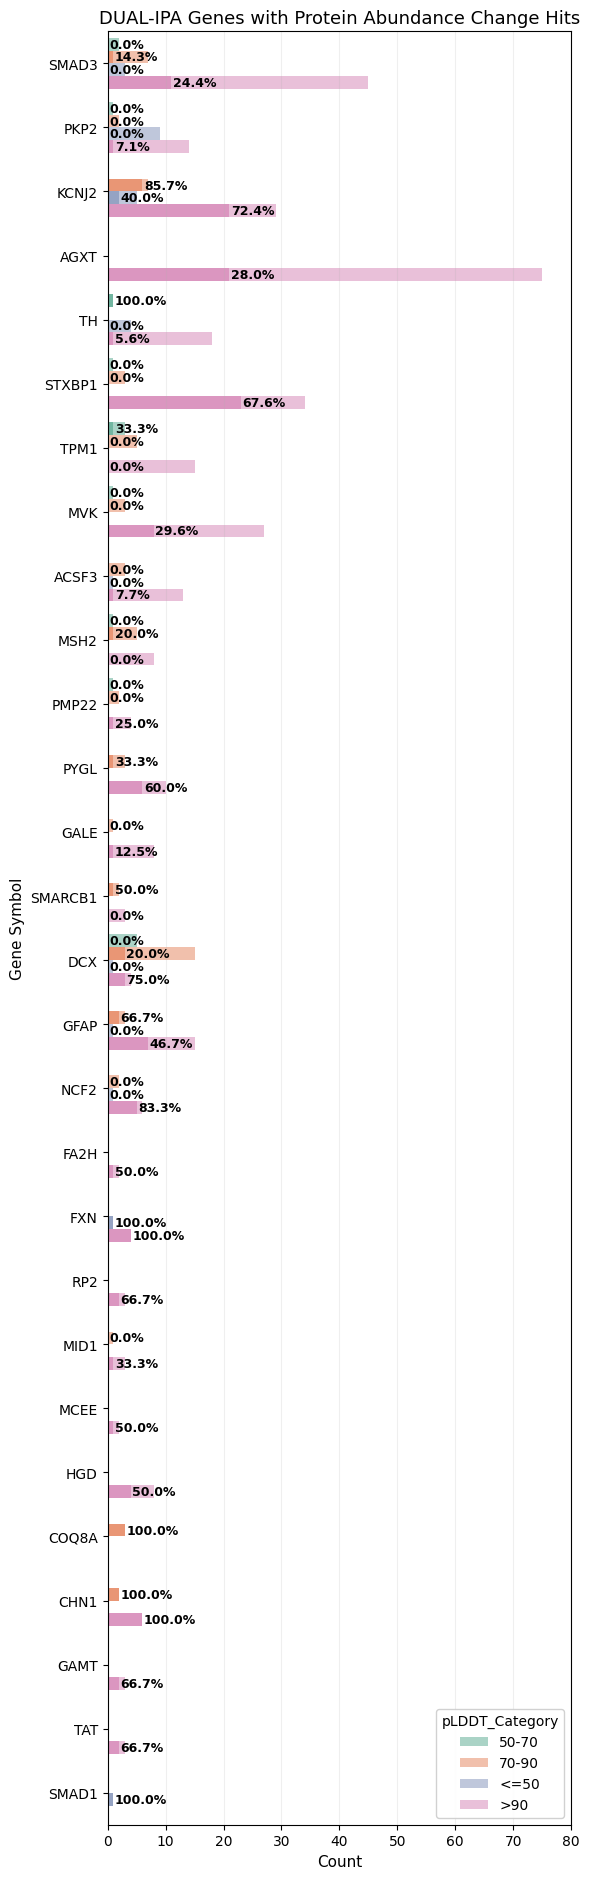

In [185]:
dual_clean_all = dual_ipa_df.filter(
    pl.col("pLDDT_Category").is_not_null()
).group_by(
    ["symbol","pLDDT_Category"]
).len().rename(
    {"len": "total_counts"}
)

dual_clean_hits_all = dual_ipa_df.filter(
    (pl.col("pLDDT_Category").is_not_null()) & (pl.col("dualipa_abund_change")) ##,"3_Conflicting","4_VUS"
).group_by(
    ["symbol","pLDDT_Category"]
).len().rename(
    {"len": "hit_counts"}
)

dual_hits_all = dual_clean_all.join(
    dual_clean_hits_all,
    on=["symbol","pLDDT_Category"],
    how="left"
).fill_null(0).with_columns(
    (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
).join(dual_gene, on="symbol").sort(
    "total_counts_all","symbol","pLDDT_Category", 
    descending=[True, True, False]
)

genes_with_hits = dual_hits_all.filter(pl.col("hit_perc")>0)["symbol"].unique()
dual_hits_all_res = plot_gene_level_summary(dual_hits_all.filter(pl.col("symbol").is_in(genes_with_hits)), 
                                            "DUAL-IPA Genes with Protein Abundance Change Hits", 
                                            xlim=(0,80), cat="pLDDT_Category")
# dual_hits_no_res = plot_gene_level_summary(dual_hits_all.filter(~pl.col("symbol").is_in(genes_with_hits)).sort(
#     "total_counts_all","symbol","RSA_Category", 
#     descending=[True, True, False]
# ), "DUAL-IPA Genes with NO Protein Abundance Change Hits", xlim=(0,55), cat="RSA_Category")

In [189]:
# dual_ipa_df.filter(
#     pl.col("pLDDT_Category").is_not_null()
# ).group_by(
#     ["symbol","pLDDT_Category"]
# ).len().rename(
#     {"len": "total_counts"}
# ).unique("symbol")